# Read the host counters of each run

You'll read the host CPU counters recorded with `main`, compare them across the systems, and check whether they explain the slow tuolumne runs of [Check how repeatable the runs are](09-spread-and-repeatability.ipynb).
It takes about 10 minutes of your time on a compute node.

## Before you start

Run the kernel inside an allocation and open the full sweep, as in [Measure the flop rate as processes share a node](06-flop-rate-as-processes-share-a-node.ipynb).

In [1]:
from dftracer.utils import Indexer, TraceViewer, col

TRACE = "/usr/workspace/genesis-wisdom/dftracer-traces/genesis-sweep/genesis.pfw.gz"
INDEX = "../data/full-index"
with Indexer(files=[TRACE], index_dir=INDEX) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(TRACE, INDEX)
print(runs.shape)

(9624, 10)


In [2]:
import os

import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)

## 1. Read the CPU counters of main

Host counters have `scope` `host`.
The `cpu.*` ones are gauges in percent, and `v.avg` is their mean over the samples that fell in `main`.

In [3]:
cpu = tv.filter(
    (col("gtype") == "counter") & (col("path") == "main") & col("metric").str.startswith("cpu.")
).collect()
wide = cpu.pivot_table(index="run", columns="metric", values="v.avg", aggfunc="mean")
wide = wide[["run", "cpu.user_pct", "cpu.system_pct", "cpu.idle_pct"]].merge(runs, on="run")
print(wide.shape)

(8741, 13)


## 2. Compare the systems

The host counters cover the whole node, not only the cores of the run.

In [4]:
print(wide.groupby("system")[["cpu.user_pct", "cpu.system_pct", "cpu.idle_pct"]].median())

     system  cpu.user_pct  cpu.system_pct  cpu.idle_pct
0    matrix     28.886367        0.080287     70.872782
1     tioga      4.164911        0.845927     94.520450
2  tuolumne      8.855694        0.695836     89.887313


Most of each node is idle during `main`, because a run uses only some of its cores.

## 3. Check the slow tuolumne runs

Take the tuolumne settings whose slowest run is more than 5 times its fastest, and compare the host values of their slow and fast runs.

In [5]:
main = tv.filter((col("gtype") == "func") & (col("path") == "main")).collect()
main = main.assign(t=main["dur.p50"] / 1e6)[["run", "t"]].merge(wide, on="run")
tuo = main[main["system"] == "tuolumne"].to_pandas()
setting = ["app", "unique_input", "nodes", "ppn"]
tuo["slow"] = tuo["t"] > 5 * tuo.groupby(setting)["t"].transform("min")
mixed = tuo[tuo.groupby(setting)["slow"].transform("any")]
cpu_cols = ["cpu.user_pct", "cpu.system_pct", "cpu.idle_pct"]
print(mixed.groupby("slow")[cpu_cols + ["t"]].median())
print(mixed.groupby("slow").size())

       cpu.user_pct  cpu.system_pct  cpu.idle_pct         t
slow                                                       
False     13.595090        0.933743     85.180263  0.318212
True      13.594509        1.125239     84.597725  5.028158
slow
False    216
True      45
dtype: int64


The slow runs take about 16 times longer, but their host CPU looks the same as that of the fast runs.

In [6]:
import numpy as np

tuo["log_t"] = np.log(tuo["t"])
print(tuo[cpu_cols + ["log_t"]].corr()["log_t"].round(2))

cpu.user_pct      0.05
cpu.system_pct    0.10
cpu.idle_pct     -0.06
log_t             1.00
Name: log_t, dtype: float64


Over all tuolumne runs, no host CPU counter follows the time of `main`.

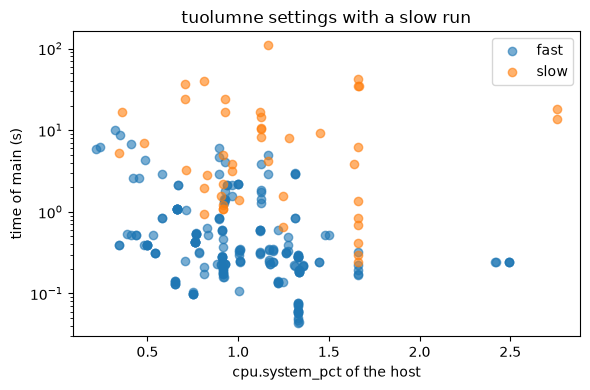

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for slow, rows in mixed.groupby("slow"):
    ax.scatter(rows["cpu.system_pct"], rows["t"], label="slow" if slow else "fast", alpha=0.6)
ax.set_yscale("log")
ax.set_xlabel("cpu.system_pct of the host")
ax.set_ylabel("time of main (s)")
ax.set_title("tuolumne settings with a slow run")
ax.legend()
fig.tight_layout()
fig.savefig("../figures/host-split.png", dpi=120)
plt.show()

So busy CPUs on the node don't explain the slow runs.
The cause is outside what the host CPU counters measure, such as the network or the file system, and this trace alone doesn't say which.

## What you built

You compared the host CPU counters across systems and showed that they don't explain the slow tuolumne runs.

- Back to the start: [Count the runs in a genesis trace](01-count-the-runs.ipynb)